本笔记本从 2026-10-07 的 USD/SLE 收盘汇率出发，模拟随后一年的每日汇率路径。使用 [USDSLE1DICE.csv](../data/cleaned/USDSLE1DICE.csv) 中的 `close`，以历史对数收益率的均值和标准差校准模型，不加入宏观因子、AR 项或事件 dummy。汇率单位为 **SLE per USD**，数值上升表示利昂相对美元贬值。

选择对数差分：
    $$
    r_t=\ln\left(\frac{S_t}{S_{t-1}}\right)
    =\ln S_t-\ln S_{t-1}
    =\Delta\ln S_t
    $$
进行模拟，然后使用变化量和汇率数据还原为汇率水平。**正态分布是对每个更新日的对数收益率所作的假设；一年后的汇率水平理论上应该服从对数正态分布。** 

This notebook generates daily USD/SLE paths for the 12 months after 7 October 2026. It estimates a constant mean and volatility from the same close-price series, without factor regression. Gaussian log returns are compounded into positive FX levels. The terminal FX level has a lognormal distribution under these assumptions.


In [1]:
# import packages
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display


下面集中设置模拟次数、随机种子、预测起点及期限。默认使用 1,000 条独立路径，固定种子保证结果可以复现。预测期按 12 个日历月计算。

原始文件在周五、周六沿用上一日汇率，本次在这些日期将模拟收益率设为 0，其余日期抽取随机收益率，并输出每个日历日的汇率。

The constants define the path count, seed, forecast origin, and horizon. Friday and Saturday carry forward the previous simulated level, following this dataset's date convention. 


In [2]:
# set constants
N_SIMULATIONS = 1_000
RANDOM_SEED = 1145141919810
FORECAST_ORIGIN = pd.Timestamp("2026-10-07")
FORECAST_MONTHS = 12
CALIBRATION_START = pd.Timestamp("2022-07-19")
UNCHANGED_WEEKDAYS = (4, 5)  # pandas: Monday=0; Friday=4, Saturday=5
HISTOGRAM_BINS = 40

DATA_RELATIVE_PATH = Path("data/cleaned/USDSLE1DICE.csv")
FORECAST_END = FORECAST_ORIGIN + pd.DateOffset(months=FORECAST_MONTHS)

if N_SIMULATIONS < 2 or FORECAST_MONTHS < 1:
    raise ValueError("Use at least two paths and a positive forecast horizon.")
if CALIBRATION_START >= FORECAST_ORIGIN:
    raise ValueError("The calibration start must precede the forecast origin.")


下面读取 `close`，检查日期、缺失值与汇率正值，并在计算收益率之前截取截至预测起点的数据。起始汇率和校准收益率均取自同一个文件，避免混用其他文件的报价口径。本文件从 2022-07-19 开始，因此本次校准仅覆盖该日到 2026-10-07。

代码检查校准窗口的日历日期是否齐全，不补造缺失价格，也不修改 CSV。预测路径生成时不会使用起点之后的实际数据。

The data block validates dates and positive closes, then selects the historical window before computing returns. Both calibration returns and the initial FX level come from the same file. Its available history starts on 19 July 2022. No data files are written.


In [ ]:
# load df and validate data
data_candidates = [DATA_RELATIVE_PATH, Path("..") / DATA_RELATIVE_PATH]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Run from the project root or the notebook directory.")

raw_prices = pd.read_csv(data_path)
if not {"date", "close"}.issubset(raw_prices.columns):
    raise ValueError("The input file must contain date and close columns.")

dates = pd.to_datetime(raw_prices["date"].astype(str), format="%Y%m%d", errors="raise")
prices = pd.Series(
    pd.to_numeric(raw_prices["close"], errors="raise").to_numpy(dtype=float),
    index=pd.DatetimeIndex(dates, name="date"),
    name="USD_SLE",
).sort_index()

if prices.index.has_duplicates or prices.index.hasnans:
    raise ValueError("Dates must be unique and non-missing.")
if not np.isfinite(prices.to_numpy()).all() or prices.le(0).any():
    raise ValueError("All close prices must be finite and strictly positive.")
if CALIBRATION_START not in prices.index or FORECAST_ORIGIN not in prices.index:
    raise ValueError("The calibration start and forecast origin must exist in the price file.")

calibration_prices = prices.loc[CALIBRATION_START:FORECAST_ORIGIN].copy()
expected_dates = pd.date_range(CALIBRATION_START, FORECAST_ORIGIN, freq="D")
if not calibration_prices.index.equals(expected_dates):
    raise ValueError("The calibration window contains missing calendar dates.")

# double check data source
initial_fx = float(calibration_prices.loc[FORECAST_ORIGIN])
data_summary = pd.DataFrame([{
    "calibration_start": calibration_prices.index.min().date(),
    "forecast_origin": FORECAST_ORIGIN.date(),
    "close_observations": len(calibration_prices),
    "initial_SLE_per_USD": initial_fx,
    "forecast_start": (FORECAST_ORIGIN + pd.Timedelta(days=1)).date(),
    "forecast_end": FORECAST_END.date(),
}])
display(data_summary)


,calibration_start,forecast_origin,close_observations,initial_SLE_per_USD,forecast_start,forecast_end
0,2022-07-19,2026-10-07,1542,22.92,2026-10-08,2027-10-07


下面计算日对数收益率。周五、周六按数据约定单独处理，其余日期保留全部收益，包括零值。每个更新日使用同一个均值 \(\hat\mu\) 和样本标准差：

$$
\hat\sigma
=
\sqrt{
\frac{1}{n-1}\sum_{t=1}^{n}(r_t-\hat\mu)^2
},
\qquad
\hat\mu=\frac{1}{n}\sum_{t=1}^{n}r_t.
$$

收益率以小数计量，例如 0.01 表示 1% 的对数变化。这里的μ hat是对数收益均值。表格同时列出最大绝对变动，方便判断波动率是否受到少数观察值影响；这些观察值全部保留。

The model uses the sample mean and standard deviation of log returns on update dates. Returns are in decimal units. Since the mean is estimated log returns. Large historical moves remain in the sample and are shown for context.


In [4]:
calendar_log_returns = np.log(calibration_prices).diff().dropna()
unchanged_history = calendar_log_returns.index.dayofweek.isin(UNCHANGED_WEEKDAYS)
if not np.allclose(
    calendar_log_returns.loc[unchanged_history].to_numpy(), 0.0, rtol=0.0, atol=1e-12
):
    raise ValueError("Historical carry-forward weekdays contain changes; review the calendar setting.")

calibration_returns = calendar_log_returns.loc[~unchanged_history].copy()
if len(calibration_returns) < 2:
    raise ValueError("At least two update-date returns are required.")

mu = float(calibration_returns.mean())
sigma = float(calibration_returns.std(ddof=1))
if not np.isfinite(sigma) or sigma <= 0:
    raise ValueError("A positive, finite volatility is required for this simulation.")

largest_move_date = calibration_returns.abs().idxmax()
calibration_summary = pd.DataFrame([{
    "update_return_observations": len(calibration_returns),
    "mean_log_return": mu,
    "std_log_return": sigma,
    "mean_log_return_pct": 100 * mu,
    "std_log_return_pct": 100 * sigma,
    "zero_return_share": float(calibration_returns.eq(0).mean()),
    "largest_move_date": largest_move_date.date(),
    "largest_log_return_pct": 100 * float(calibration_returns.loc[largest_move_date]),
}])
display(calibration_summary)

largest_dates = calibration_returns.abs().nlargest(5).index
largest_moves = pd.DataFrame({
    "previous_close": calibration_prices.shift(1).loc[largest_dates],
    "close": calibration_prices.loc[largest_dates],
    "log_return_pct": 100 * calibration_returns.loc[largest_dates],
}).rename_axis("date")
display(largest_moves)


,update_return_observations,mean_log_return,std_log_return,mean_log_return_pct,std_log_return_pct,zero_return_share,largest_move_date,largest_log_return_pct
0,1101,0.00047,0.015486,0.047006,1.548576,0.222525,2023-06-19,-24.686008


,previous_close,close,log_return_pct
date,,,
2023-06-19,22.40,17.50,-24.686008
2026-06-08,22.70,24.35,7.016693
2026-06-09,24.35,22.71,-6.972649
2026-05-20,24.35,22.74,-6.840636
2026-05-13,22.75,24.35,6.796670


下面对每条路径 \(j=1,\dots,M\)、每个更新日 \(t=1,\dots,T\) 独立抽取 \(z_{t,j}\sim N(0,1)\)，生成对数收益率 \(r_{t,j}=\hat\mu+\hat\sigma z_{t,j}\)，并累计还原汇率：

For each path \(j=1,\dots,M\) and each update date \(t=1,\dots,T\), draw independent \(z_{t,j}\sim N(0,1)\), generate the log-return \(r_{t,j}=\hat\mu+\hat\sigma z_{t,j}\), and reconstruct the exchange rate by accumulation:

$$
z_{t,j}\sim N(0,1),
\qquad
r_{t,j}=\hat\mu+\hat\sigma\,z_{t,j},
\qquad
S_{t,j}=S_0\exp\left(\sum_{u=1}^{t}r_{u,j}\right).
$$

In [5]:
forecast_dates = pd.date_range(
    FORECAST_ORIGIN + pd.Timedelta(days=1), FORECAST_END, freq="D"
)
update_mask = ~forecast_dates.dayofweek.isin(UNCHANGED_WEEKDAYS)
n_update_days = int(update_mask.sum())
if n_update_days < 1:
    raise ValueError("The forecast horizon must include at least one update date.")

rng = np.random.default_rng(RANDOM_SEED)
simulated_log_returns = np.zeros((len(forecast_dates), N_SIMULATIONS))
simulated_log_returns[update_mask, :] = rng.normal(
    loc=mu, scale=sigma, size=(n_update_days, N_SIMULATIONS)
)

cumulative_log_returns = np.vstack([
    np.zeros((1, N_SIMULATIONS)),
    np.cumsum(simulated_log_returns, axis=0),
])
path_dates = pd.DatetimeIndex([FORECAST_ORIGIN]).append(forecast_dates)
fx_paths = pd.DataFrame(
    initial_fx * np.exp(cumulative_log_returns),
    index=path_dates.rename("date"),
    columns=pd.Index(
        [f"path_{i + 1:04d}" for i in range(N_SIMULATIONS)], name="simulation"
    ),
)

if not np.isfinite(fx_paths.to_numpy()).all() or fx_paths.le(0).any().any():
    raise ValueError("Generated FX levels must remain finite and positive.")

path_quantiles = pd.DataFrame(
    np.quantile(fx_paths.to_numpy(), [0.05, 0.50, 0.95], axis=1).T,
    index=fx_paths.index,
    columns=["P05", "P50", "P95"],
)
terminal_fx = fx_paths.iloc[-1].rename("terminal_SLE_per_USD")

display(pd.DataFrame([{
    "paths": N_SIMULATIONS,
    "forecast_calendar_days": len(forecast_dates),
    "random_update_days": n_update_days,
    "carry_forward_days": int((~update_mask).sum()),
    "seed": RANDOM_SEED,
}]))


,paths,forecast_calendar_days,random_update_days,carry_forward_days,seed
0,1000,365,261,104,1145141919810


**第一张图展示全部模拟路径，并叠加各日的中位数与 5%、95% 分位数。**纵轴是还原后的 USD/SLE 汇率水平。分位线展示给定模型下的横截面分布；各日中位数连接而成的线不一定对应某一条实际抽样路径，5% 至 95% 区间也不代表整条路径有 90% 的概率始终位于其中。

**The first chart shows every simulated FX path, together with the pointwise median and 5th/95th percentiles.** The percentile bounds describe each date's marginal distribution, rather than simultaneous coverage of a complete path.


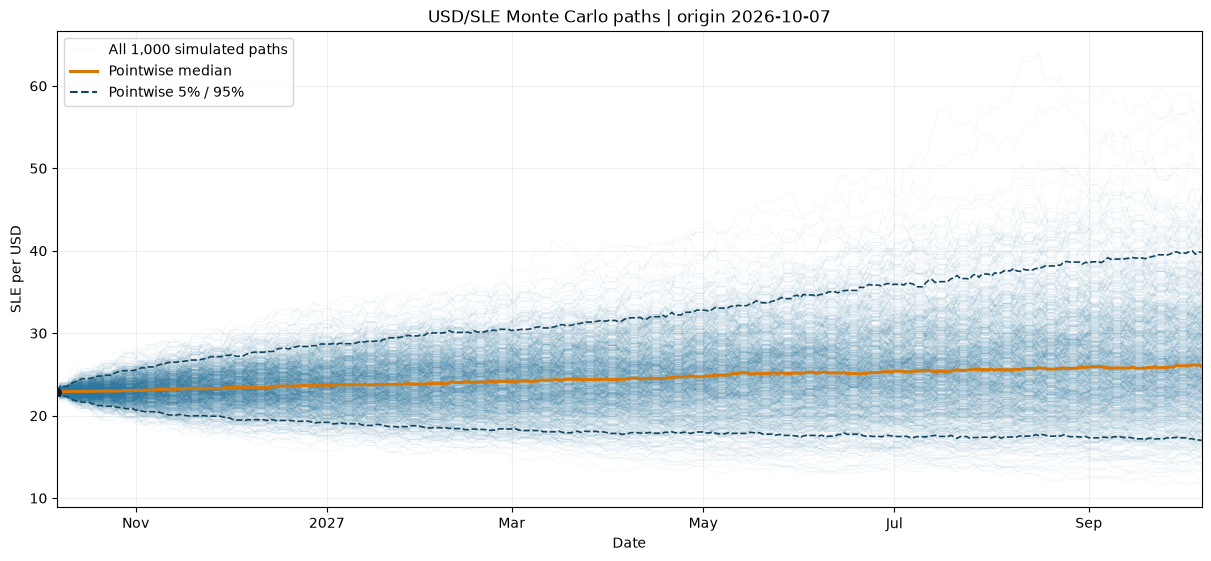

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.5), layout="constrained")
path_lines = ax.plot(
    fx_paths.index, fx_paths.to_numpy(),
    color="#2878A3", alpha=0.055, linewidth=0.6,
)
path_lines[0].set_label(f"All {N_SIMULATIONS:,} simulated paths")
ax.plot(
    path_quantiles.index, path_quantiles["P50"],
    color="#D97706", linewidth=2.2, label="Pointwise median",
)
ax.plot(
    path_quantiles.index, path_quantiles[["P05", "P95"]],
    color="#16445B", linestyle="--", linewidth=1.2,
)
ax.plot([], [], color="#16445B", linestyle="--", label="Pointwise 5% / 95%")
ax.scatter([FORECAST_ORIGIN], [initial_fx], color="#111827", s=28, zorder=5)
ax.set(
    title=f"USD/SLE Monte Carlo paths | origin {FORECAST_ORIGIN:%Y-%m-%d}",
    xlabel="Date",
    ylabel="SLE per USD",
    xlim=(FORECAST_ORIGIN, FORECAST_END),
)
locator = mdates.AutoDateLocator(minticks=5, maxticks=9)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=0.2)
ax.legend(loc="upper left")
plt.show()


第二张图展示一年后所有路径终点的密度直方图，叠加该模型的理论对数正态密度。

The second figure shows the density histogram of the endpoints of all paths one year later, with the theoretical log-normal density of this model superimposed.

,simulation_SLE_per_USD,theory_SLE_per_USD
Terminal date: 2027-10-07,,
Mean,26.9991,26.7355
Standard deviation,6.8811,6.7947
P05,17.0003,17.1704
Median (P50),26.0283,25.9117
P95,39.8118,39.1032


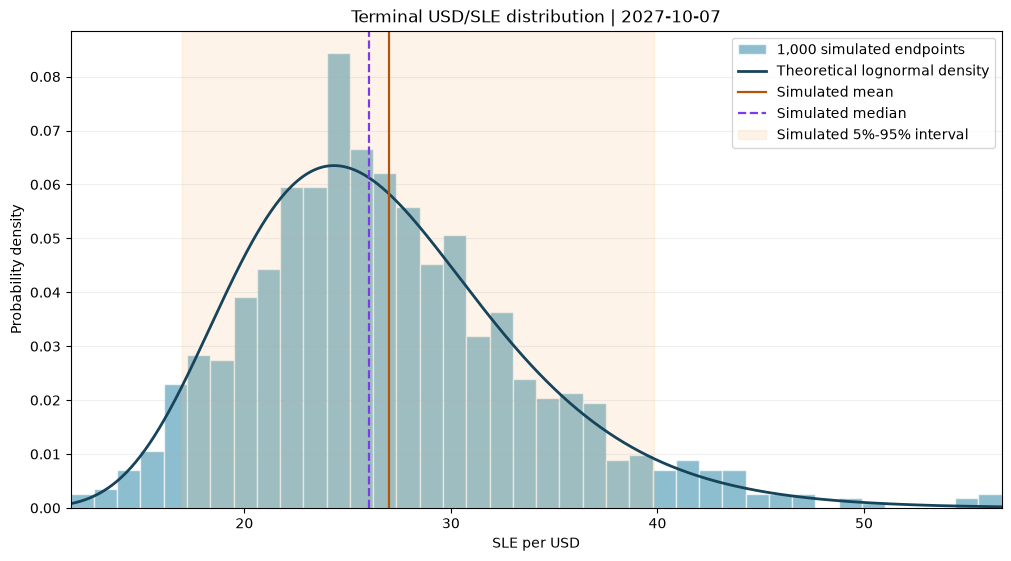

In [7]:
terminal_log_location = np.log(initial_fx) + n_update_days * mu
terminal_log_scale = np.sqrt(n_update_days) * sigma
terminal_log_variance = terminal_log_scale ** 2
normal_reference = NormalDist()

theoretical_mean = float(np.exp(terminal_log_location + terminal_log_variance / 2))
theoretical_std = float(np.sqrt(
    np.expm1(terminal_log_variance)
    * np.exp(2 * terminal_log_location + terminal_log_variance)
))
quantile_probabilities = [0.05, 0.50, 0.95]
theoretical_quantiles = np.exp(
    terminal_log_location
    + terminal_log_scale
    * np.array([normal_reference.inv_cdf(p) for p in quantile_probabilities])
)
simulation_quantiles = terminal_fx.quantile(quantile_probabilities).to_numpy()

terminal_summary = pd.DataFrame(
    {
        "simulation_SLE_per_USD": [
            terminal_fx.mean(), terminal_fx.std(ddof=1), *simulation_quantiles,
        ],
        "theory_SLE_per_USD": [
            theoretical_mean, theoretical_std, *theoretical_quantiles,
        ],
    },
    index=["Mean", "Standard deviation", "P05", "Median (P50)", "P95"],
)
terminal_summary.index.name = f"Terminal date: {FORECAST_END:%Y-%m-%d}"
display(terminal_summary.round(4))

theory_plot_bounds = np.exp(
    terminal_log_location
    + terminal_log_scale
    * np.array([normal_reference.inv_cdf(0.001), normal_reference.inv_cdf(0.999)])
)
density_grid = np.linspace(
    min(float(terminal_fx.min()), theory_plot_bounds[0]),
    max(float(terminal_fx.max()), theory_plot_bounds[1]),
    600,
)
theoretical_density = np.exp(
    -0.5 * ((np.log(density_grid) - terminal_log_location) / terminal_log_scale) ** 2
) / (density_grid * terminal_log_scale * np.sqrt(2 * np.pi))

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.hist(
    terminal_fx, bins=HISTOGRAM_BINS, density=True,
    color="#4F9CB7", alpha=0.65, edgecolor="white",
    label=f"{N_SIMULATIONS:,} simulated endpoints",
)
ax.plot(
    density_grid, theoretical_density,
    color="#16445B", linewidth=2, label="Theoretical lognormal density",
)
ax.axvline(
    float(terminal_fx.mean()), color="#B45309",
    linewidth=1.6, label="Simulated mean",
)
ax.axvline(
    float(simulation_quantiles[1]), color="#7C3AED",
    linestyle="--", linewidth=1.6, label="Simulated median",
)
ax.axvspan(
    simulation_quantiles[0], simulation_quantiles[2],
    color="#FDBA74", alpha=0.16, label="Simulated 5%-95% interval",
)
ax.set(
    title=f"Terminal USD/SLE distribution | {FORECAST_END:%Y-%m-%d}",
    xlabel="SLE per USD",
    ylabel="Probability density",
    xlim=(density_grid[0], density_grid[-1]),
)
ax.grid(axis="y", alpha=0.2)
ax.legend()
plt.show()
